# Noiseless XYZ Sampler

In [1]:
# import system libraries
import logging
import sys, copy
# import scientific libraries
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from scipy.interpolate import InterpolatedUnivariateSpline as spline
import h5py
import pandas as pd
# import data analysis libraries
from ldc.waveform.lisabeta import FastBHB
import lisabeta.lisa.lisa as lisa

from ldc.lisa.noise import AnalyticNoise, get_noise_model
from chainconsumer import Chain, ChainConsumer, make_sample, Truth
import lisaconstants
# import sampler libraries
from eryn.ensemble import EnsembleSampler
from eryn.state import State
from eryn.prior import uniform_dist, ProbDistContainer

from lisabeta.lisa.lisa import EvaluateTDIFreqseries
import lisabeta.tools.pyspline as pyspline
import lisabeta.lisa.lisatools as lisatools
import lisabeta.tools.pytools as pytools
from ldc.common import tools
from ldc.waveform.waveform import HpHc
import scipy.signal

#imports all dependencies and homebrewed functions
import LISA_TTL_Functions as foc

In [2]:
save_name = 'XYZ_Original_source_1'

In [3]:
'''
filename = '/Users/corinnekomlodi/Desktop/LDC2_sangria_training_v2.h5'
catpath = 'sky/mbhb/cat'
pMBHB_ldc = foc.sangria_source(filename, catpath, 2)
print(pMBHB_ldc)
pMBHB_ldc['Distance'] = pMBHB_ldc['Distance']*10
#pMBHB_ldc['Distance'] = 2500
print(pMBHB_ldc)
'''

#set up the injection
#'''
pMBHB_ldc = {'EclipticLatitude': -0.30300442294174235,
 'EclipticLongitude': 1.2925183861048521,
 'PolarAngleOfSpin1': 1.2031361791056812,
 'PolarAngleOfSpin2': 2.097303543065685,
 'Spin1': 0.747377,
 'Spin2': 0.8388,
 'Mass1': 1323277.47932, #original 1323277.47932
 'Mass2': 612485.5060299999, #original 612485.5060299999
 'CoalescenceTime': 11526944.921879262,
 'PhaseAtCoalescence': 1.2201968860015653,
 'InitialPolarAngleL': 2.6919824500032945,
 'InitialAzimuthalAngleL': 1.808398497592109,
 'Redshift': 1.73941,
 'Distance': 13470.983559, # original
 'ObservationDuration': 31558149.763545603, # 1.0007023643945205 years
 'Cadence': 3.0}
 #'''

In [4]:
#establish t_min, max, separation and number of samples
t_min = 0
t_max = pMBHB_ldc["CoalescenceTime"]+1000
dt = 0.25
df = 1/t_max

t = np.arange(t_min, t_max, dt)

#set up the injection in lisabeta terms
FBH = FastBHB("MBHB", T=t_max, delta_t=dt, approx="IMRPhenomHM")
pMBHB = FBH.rename_as_lisabeta(pMBHB_ldc)

pMBHB['psi'] += np.pi
pMBHB['phi'] -= np.pi
#print(pMBHB)

In [5]:
#Set up the Frequency Vector
fmin = 1e-5
fmax = 1
ndata = int(t_max/dt)
df = 1/t_max

# Get the full frequencies
if (ndata % 2)==0:              # Get the number of frequencies
    nfft = int((ndata/2)+1)
else:
    nfft = int((ndata+1)/2)

F = df*nfft                 # make the positive frequency vector
fvec = np.arange(0, F, df)

# Get the frequencies of interest
f_inds = np.where(np.logical_and(fvec >= fmin, fvec < fmax))
fvec = fvec[f_inds]
fvec = fvec[fvec>0]
print(len(fvec))

#downsample fvec
if len(fvec) != 1441:
    fvec = fvec[::8000]  
    fvec = np.ascontiguousarray(fvec)
else:
    pass

print(len(fvec))
df = fvec[1]-fvec[0]

11527829
1441


In [6]:
def invNpsd(XX, XY): #This changes if arm lengths are non equal
    diagonalNpsd = (XX+XY)/(XX**2+XX*XY-2*XY**2)
    offdiagNpsd = -XY/(XX**2+XX*XY-2*XY**2)
    return diagonalNpsd, offdiagNpsd

def AETtoXYZ(A, E, T):
    X = (1/6)*(-3*np.sqrt(2)*A + np.sqrt(6)*E + 2*np.sqrt(3)*T)
    Y = (1/3)*(-np.sqrt(6)*E + np.sqrt(3)*T)
    Z = (1/6)*(3*np.sqrt(2)*A + np.sqrt(6)*E + 2*np.sqrt(3)*T)
    return X, Y, Z

In [7]:
#Waveform Parameters
waveform_params_smbh = {
    "minf": 1e-5,
    "maxf": 1,
    "t0": 0.0,
    "timetomerger_max": 1.0,
    "tmax": 1.0,
    "TDI": "TDI2AET",
    "LISAconst": "Proposal",
    "responseapprox": "full",
    "frozenLISA": False,
    "TDIrescaled": False,
    "modes": None,
    # Waveform approximant and set of harmonics to use 
    "approximant": "IMRPhenomHM"
}

[(2, 2), (2, 1), (3, 3), (3, 2), (4, 4), (4, 3)]


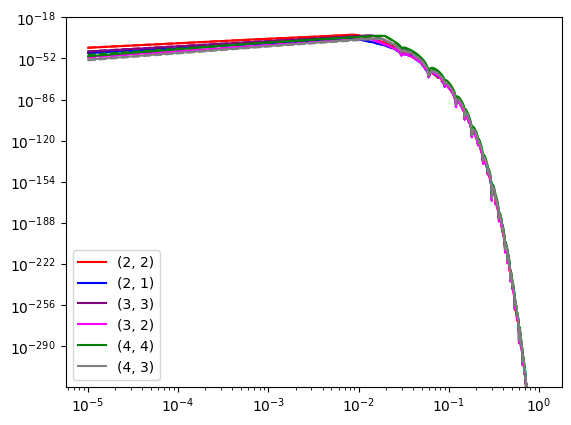

In [8]:
#Generate Data
tdisignal = lisa.GenerateLISATDISignal_SMBH(pMBHB, 
                                            gridfreq = fvec,
                                            scale_freq_hm = False,
                                            **waveform_params_smbh)
tdi = tdisignal['tdi']

modesf  = tdisignal['tdi']['modes']
colors = ['red', 'blue', 'purple', 'magenta', 'green', 'gray']
print(modesf)
A_full = np.zeros(len(fvec), dtype=complex)
E_full = np.zeros(len(fvec), dtype=complex)
T_full = np.zeros(len(fvec), dtype=complex)

for i in range(len(modesf)):
        mbh_lb = tdisignal['tdi'][modesf[i]]
        
        #phase
        splPh = mbh_lb['phase']
        #A
        splAr = mbh_lb['amp_real_chan1']
        splAi = mbh_lb['amp_imag_chan1']

        #E
        splEr = mbh_lb['amp_real_chan2']
        splEi = mbh_lb['amp_imag_chan2']

        #T
        splTr = mbh_lb['amp_real_chan3']
        splTi = mbh_lb['amp_imag_chan3']

        A_partial = np.conjugate((splAr + 1.j*splAi) * np.exp(1j*splPh))
        E_partial = np.conjugate((splEr + 1.j*splEi) * np.exp(1j*splPh))
        T_partial = np.conjugate((splTr + 1.j*splTi) * np.exp(1j*splPh))

        plt.loglog(fvec, np.abs(A_partial)**2, label = str(modesf[i]), color = colors[i])
        plt.loglog(fvec, np.abs(E_partial)**2, '--', color = colors[i])
        plt.legend()

        A_full += A_partial
        E_full += E_partial
        T_full += T_partial
    

In [9]:
DA = A_full.copy()
DE = E_full.copy()
DT = T_full.copy()

DX, DY, DZ = AETtoXYZ(DA, DE, DT)

[1.00625047e-05 7.04028346e-04 1.39799419e-03 ... 9.97932943e-01
 9.98626909e-01 9.99320874e-01]
(array([ 8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24,
       25, 26, 27, 28]),)


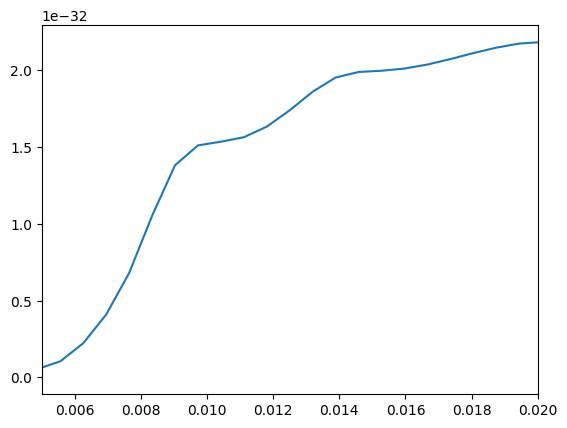

In [10]:
snr_cum = np.cumsum(np.abs(DX)**2)
plt.plot(fvec, snr_cum)
plt.xlim([.005, 2e-2])
print(fvec)
snr_mask = np.where((fvec > 0.005) & (fvec < 2e-2))
print(snr_mask)

DX = DX[snr_mask]
DY = DY[snr_mask]
DZ = DZ[snr_mask]

fvec = fvec[snr_mask]

In [11]:
#define functions needed to calculate XYZ relations and noises 
Nmodel = AnalyticNoise(fvec, model="SciRDv1")
Npsd_X = Nmodel.psd(option='X', tdi2=True)
Npsd_XY = Nmodel.psd(option='XY', tdi2=True)

diagn, offdiagn = invNpsd(Npsd_X, Npsd_XY)


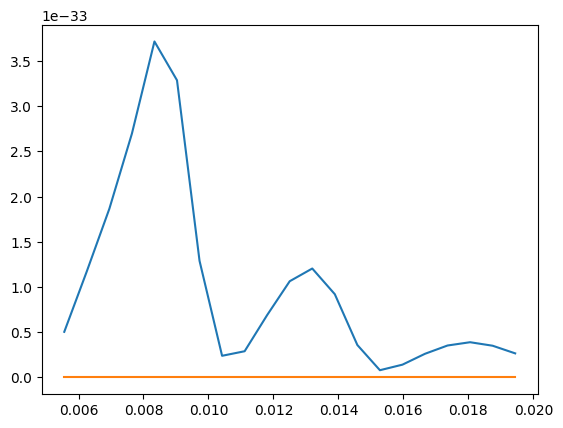

In [13]:
plt.plot(fvec, np.abs(DX)**2)
plt.plot(fvec, Npsd_X)

# Set up MCMC

In [14]:
#now we set things up for mcmc
#solving for chirpmass and ratio
m1 = pMBHB['m1']
m2 = pMBHB['m2']
q = m1/m2
Mc = (m1+m2)*(q/(1+q)**2)**0.6

src0 = pMBHB.copy()
src0["Mchirp"] = Mc
src0["q"] = q
del src0["m1"]
del src0["m2"]

keys = src0.keys()

#create the array to be altered in likelihood
#src = copy.deepcopy(src0)
print(pMBHB)
print(src0)

#Fix the things that rely on pi
#src0['phi'] = np.mod(src0['phi'], np.pi)
#src0['psi'] = np.mod(src0['psi'], np.pi)
print(src0)

{'beta': -0.30300442294174235, 'lambda': 1.2925183861048521, 'chi1': np.float64(0.26863190922667673), 'chi2': np.float64(-0.4215109787709388), 'm1': 1323277.47932, 'm2': 612485.5060299999, 'Deltat': 11526944.921879262, 'phi': -1.9213957675882278, 'dist': 13470.983559, 'psi': np.float64(1.2912226019238924), 'inc': np.float64(2.2517895222056112)}
{'beta': -0.30300442294174235, 'lambda': 1.2925183861048521, 'chi1': np.float64(0.26863190922667673), 'chi2': np.float64(-0.4215109787709388), 'Deltat': 11526944.921879262, 'phi': -1.9213957675882278, 'dist': 13470.983559, 'psi': np.float64(1.2912226019238924), 'inc': np.float64(2.2517895222056112), 'Mchirp': 772462.8571528315, 'q': 2.160504152820206}
{'beta': -0.30300442294174235, 'lambda': 1.2925183861048521, 'chi1': np.float64(0.26863190922667673), 'chi2': np.float64(-0.4215109787709388), 'Deltat': 11526944.921879262, 'phi': -1.9213957675882278, 'dist': 13470.983559, 'psi': np.float64(1.2912226019238924), 'inc': np.float64(2.2517895222056112)

In [15]:
#likelihood stuff
def whip(a, b, Npsd):
    product = np.real(a)*np.real(b) + np.imag(a)*np.imag(b)
    arg = product*Npsd
    return arg

def XYZLikelihood(pvector):
    #Build the waveform
    src = {k: v for k, v in zip(keys, pvector)}
    
    tdisignal = lisa.GenerateLISATDISignal_SMBH(src, 
                                                gridfreq=fvec, 
                                                scale_freq_hm = False,
                                                **waveform_params_smbh)
    modesf = tdisignal['tdi']['modes']

    df = fvec[1]-fvec[0]

    hA = np.zeros(len(fvec), dtype=complex)
    hE = np.zeros(len(fvec), dtype=complex)
    hT = np.zeros(len(fvec), dtype=complex)

    for i in range(len(modesf)):
        mbh_lb = tdisignal['tdi'][modesf[i]]
        
        #phase
        splPh = mbh_lb['phase']
        #A
        splAr = mbh_lb['amp_real_chan1']
        splAi = mbh_lb['amp_imag_chan1']

        #E
        splEr = mbh_lb['amp_real_chan2']
        splEi = mbh_lb['amp_imag_chan2']

        #T
        splTr = mbh_lb['amp_real_chan3']
        splTi = mbh_lb['amp_imag_chan3']

        A_partial = np.conjugate((splAr + 1.j*splAi) * np.exp(1j*splPh))
        E_partial = np.conjugate((splEr + 1.j*splEi) * np.exp(1j*splPh))
        T_partial = np.conjugate((splTr + 1.j*splTi) * np.exp(1j*splPh))

        hA += A_partial
        hE += E_partial
        hT += T_partial

    hX, hY, hZ = AETtoXYZ(hA, hE, hT)

    #where DX/Y/Z is data and hX/Y/Z is trial
    DXX = whip(DX, hX, diagn)
    DYY = whip(DY, hY, diagn)
    DZZ = whip(DZ, hZ, diagn)
    DXY = whip(DX, hY, offdiagn) + whip(DY, hX, offdiagn)
    DXZ = whip(DX, hZ, offdiagn) + whip(DZ, hX, offdiagn)
    DYZ = whip(DY, hZ, offdiagn) + whip(DZ, hY, offdiagn)

    hXX = whip(hX, hX, diagn)
    hYY = whip(hY, hY, diagn)
    hZZ = whip(hZ, hZ, diagn)
    hXY = 2*whip(hX, hY, offdiagn)
    hXZ = 2*whip(hX, hZ, offdiagn)
    hYZ = 2*whip(hY, hZ, offdiagn)


    loglik = 4*df*(np.sum([DXX, DYY, DZZ, DXY, DXZ, DYZ])-0.5*np.sum([hXX, hYY, hZZ, hXY, hXZ, hYZ]))

    return loglik

In [16]:
#Priors
day_sec = 86400

priors = {"mbh": ProbDistContainer({
    0: uniform_dist(-np.pi, np.pi), #beta
    1: uniform_dist(-np.pi/2, np.pi/2), #lambda
    2: uniform_dist(-1, 1), #chi1
    3: uniform_dist(-1, 1), #chi2
    4: uniform_dist(75*day_sec, 175*day_sec), #deltat
    5: uniform_dist(-np.pi, np.pi), #phi
    6: uniform_dist(500.0, 2000000.0), #dist 
    7: uniform_dist(0., np.pi), #psi
    8: uniform_dist(0., np.pi), #inc
    9: uniform_dist(1e4, 1e7), #mchirp 
    10: uniform_dist(1, 10), #q
})}

ndims = {"mbh": 11}

In [17]:
ntemps = 7
nwalkers = 22
nsamples = 3500
ndims = {"mbh": 11}

theta0 = np.array([[np.hstack(
          (np.random.randn(ndims["mbh"]) * 1e-8) + np.array(list(src0.values())))
          for i in range(nwalkers)]
          for _ in range(ntemps)])

start_state = State({"mbh": theta0})

import multiprocessing as mp

with mp.get_context("fork").Pool(8) as pool:
    sampler = EnsembleSampler(
        nwalkers,
        ndims,
        XYZLikelihood,
        priors,
        pool = pool,
        args=(),
        branch_names=["mbh"],
        tempering_kwargs=dict(ntemps=ntemps),
        nleaves_max=dict(mbh=1),
    )
    sampler.run_mcmc(start_state, nsamples, progress=True, store = True)

100%|██████████| 3500/3500 [01:50<00:00, 31.74it/s]


# Run the MCMC

# Outputs

In [18]:
#define truths
keys = src0.keys()
labels = list(keys)

inj=np.array(list(src0.values()))

truths = inj.flatten()
labels_final = labels

#Save Truths
truth = pd.DataFrame(data = truths , columns = ['truths'])
csv_filename_truth = save_name + "_truth.csv"
truth.to_csv(csv_filename_truth, index=False)

Chain data saved to 0mm_XYZ_Original_source_1_chains.csv


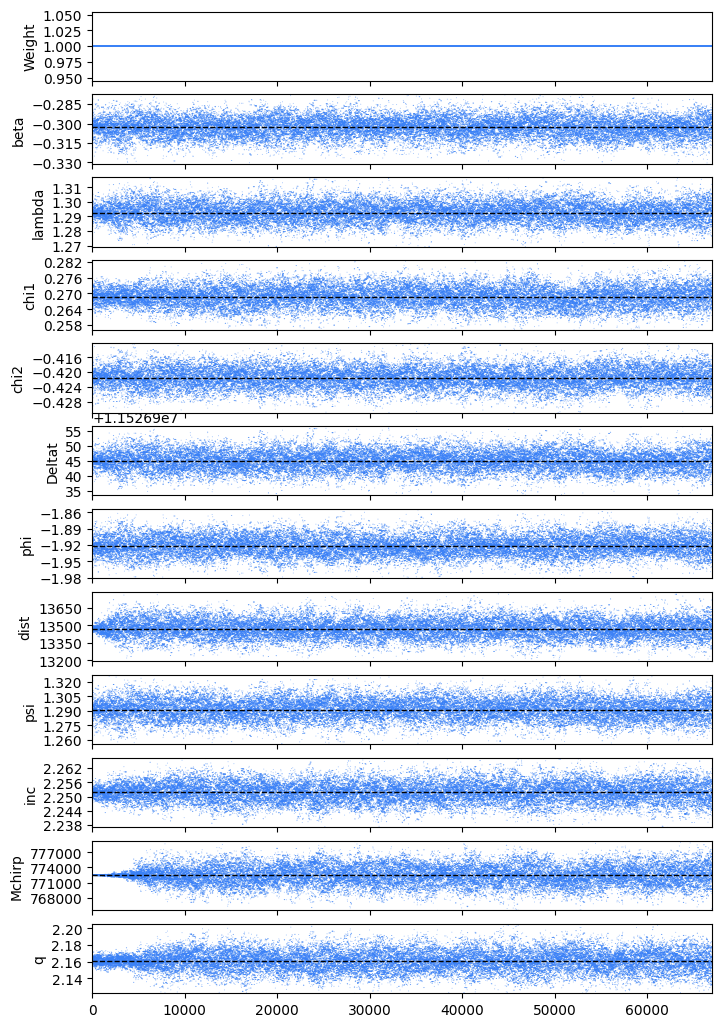

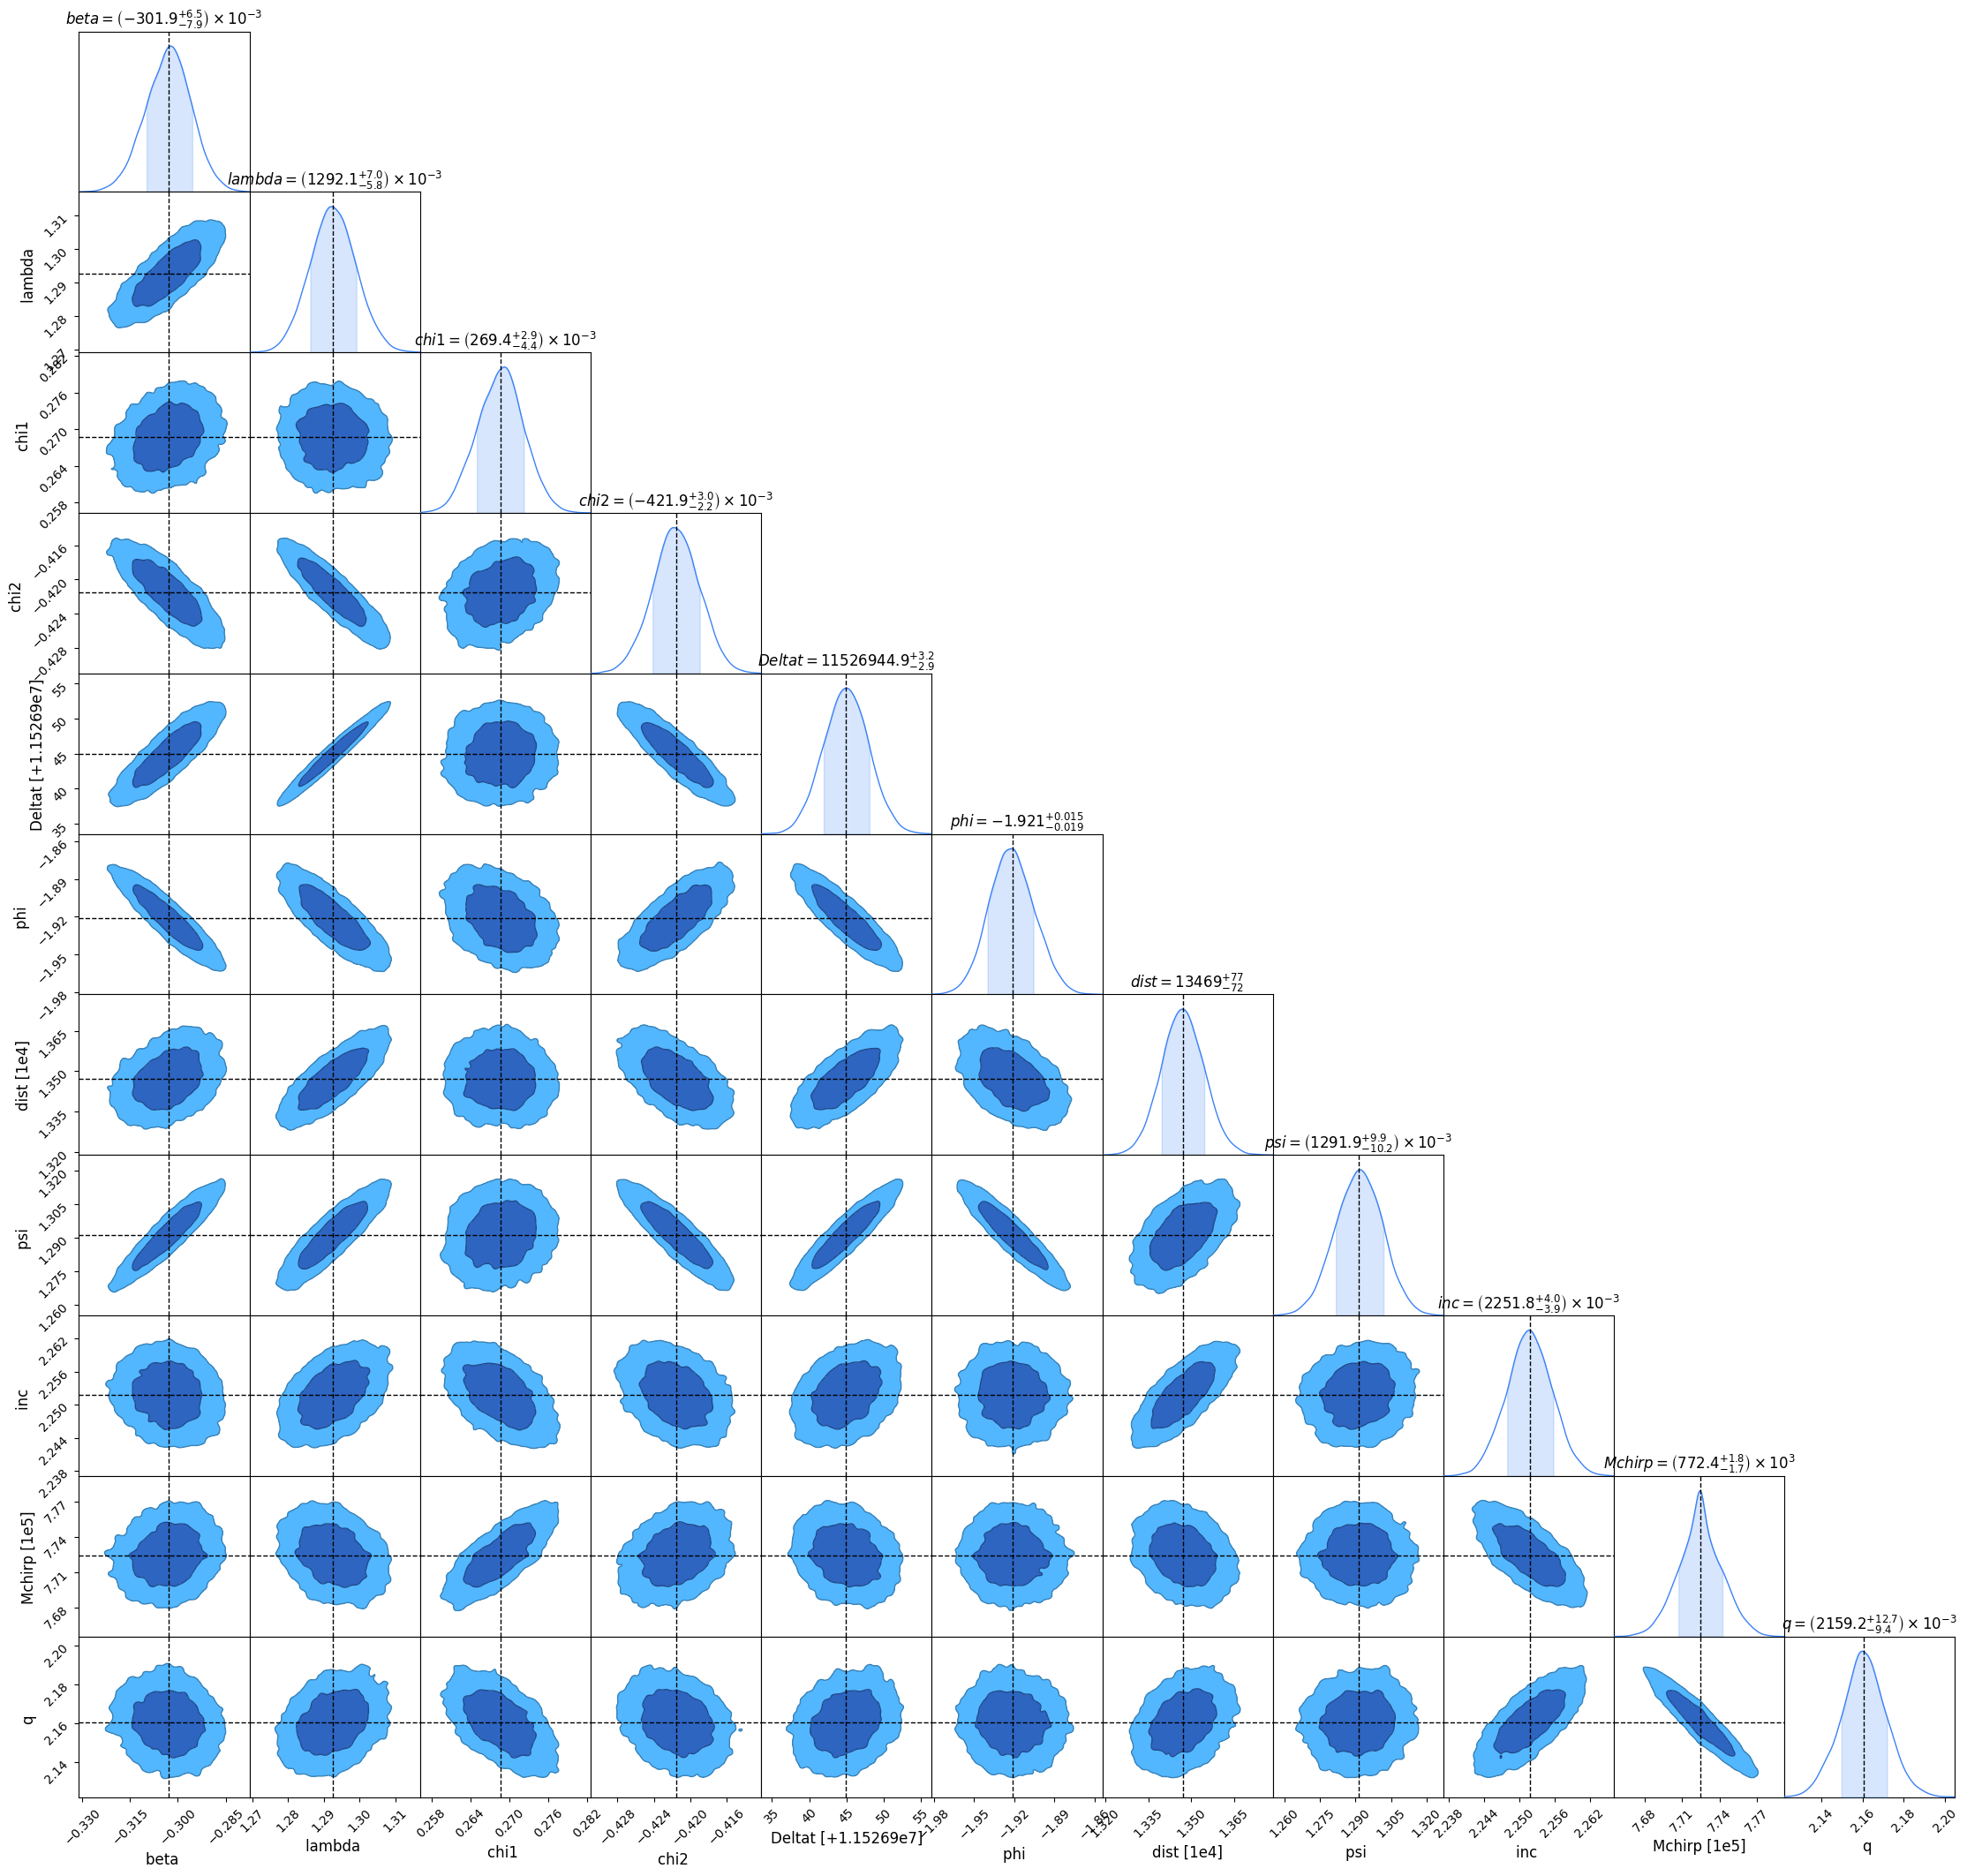

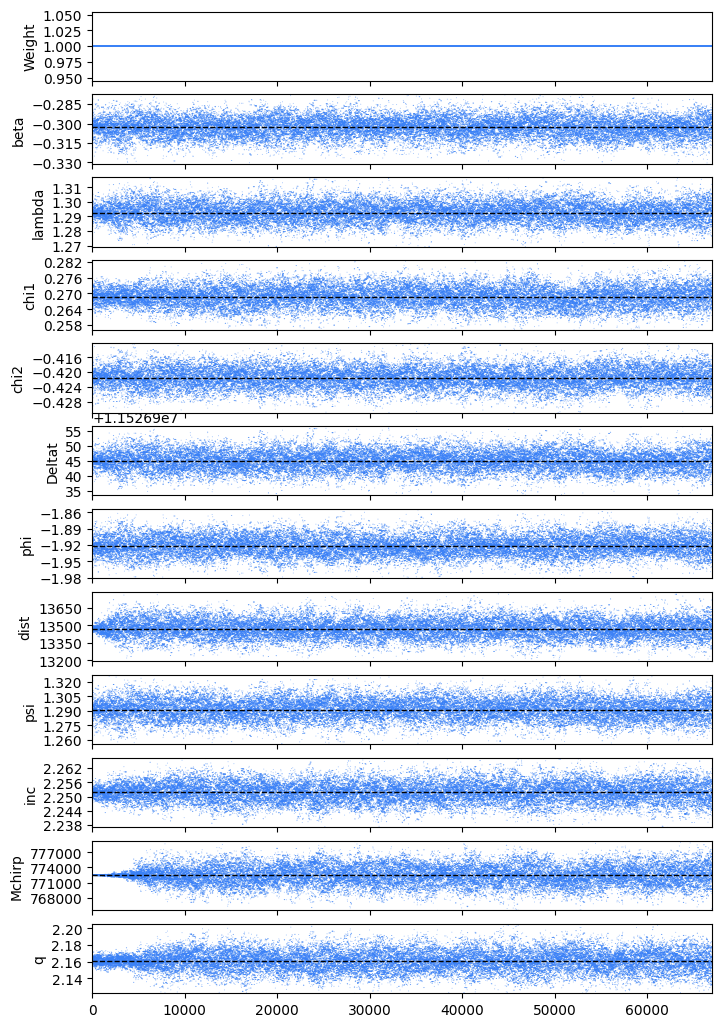

In [19]:
#plot
c = ChainConsumer()
burn = 10000

samples_2ch = sampler.get_chain()["mbh"][:, 0].reshape(-1, 11)

dfs_2chnls = pd.DataFrame(samples_2ch[burn:, :], columns = keys)

c.add_chain(Chain(samples=dfs_2chnls, name="noiseless", color="blue"))
c.add_truth(Truth(location={k:v for (k,v) in zip(labels_final,truths)}))

#Save File
csv_filename_0mm = "0mm_"+ save_name + "_chains.csv"
dfs_2chnls.to_csv(csv_filename_0mm, index=False)
print(f"Chain data saved to {csv_filename_0mm}")

#import corner
#figure = corner.corner(dfs_2chnls)

c.plotter.plot()
c.plotter.plot_walks()